In [1]:
#Load and preprocess the dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.cluster import BisectingKMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score

from scipy.cluster.hierarchy import linkage, dendrogram

df = pd.read_csv("Crime Prediction in Chicago_Dataset.csv")

df = df[df["Year"] == 2022].copy()

df = df.dropna(subset=["X Coordinate", "Y Coordinate"])

df = df[
    (df["X Coordinate"] > 0) &
    (df["Y Coordinate"] > 0)
]

print("Dataset shape:", df.shape)
print("\nFirst five records:")
print(df.head())

print("\nMissing coordinates:")
print(df[["X Coordinate", "Y Coordinate"]].isnull().sum())

Dataset shape: (74732, 22)

First five records:
         ID Case Number             Date                   Block  IUCR  \
0  12592454    JF113025  1/14/2022 15:55       067XX S MORGAN ST  2826   
1  12785595    JF346553   8/5/2022 21:00  072XX S UNIVERSITY AVE  1544   
2  12808281    JF373517  8/14/2022 14:00     055XX W ARDMORE AVE  1562   
3  12888104    JF469015  11/10/2022 3:47          072XX S MAY ST  1477   
5  12622465    JF149923  2/19/2022 10:36   010XX N FRANCISCO AVE   486   

        Primary Type                       Description  \
0      OTHER OFFENSE    HARASSMENT BY ELECTRONIC MEANS   
1        SEX OFFENSE    SEXUAL EXPLOITATION OF A CHILD   
2        SEX OFFENSE  AGGRAVATED CRIMINAL SEXUAL ABUSE   
3  WEAPONS VIOLATION        RECKLESS FIREARM DISCHARGE   
5            BATTERY           DOMESTIC BATTERY SIMPLE   

          Location Description  Arrest  Domestic  ...  Ward  Community Area  \
0                    RESIDENCE   False      True  ...  16.0              68   


In [2]:
#Select a sample and scale the features
sample_size = min(4000, len(df))

sample_df = df.sample(
    n=sample_size,
    random_state=42
).copy()

X = sample_df[["X Coordinate", "Y Coordinate"]].to_numpy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Records selected:", len(sample_df))
print("Features used: X Coordinate, Y Coordinate")

Records selected: 4000
Features used: X Coordinate, Y Coordinate


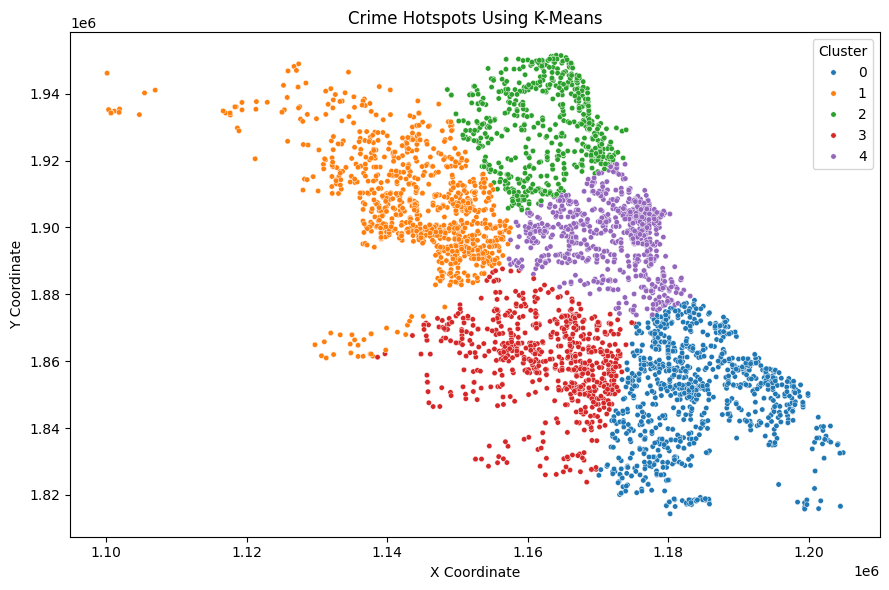

In [3]:
#Partitional clustering — K-Means
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

sample_df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=sample_df,
    x="X Coordinate",
    y="Y Coordinate",
    hue="KMeans_Cluster",
    palette="tab10",
    s=15
)
plt.title("Crime Hotspots Using K-Means")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

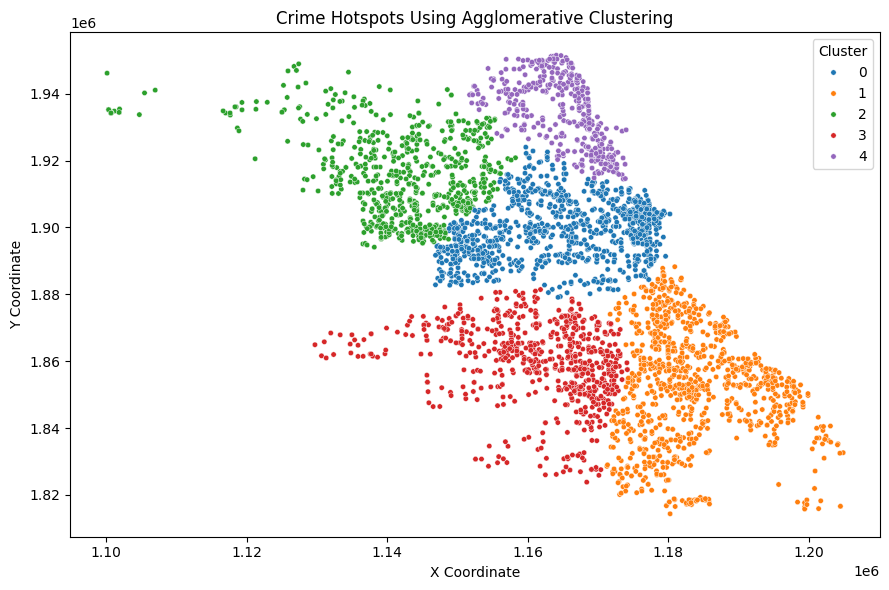

In [4]:
#Hierarchical clustering — Agglomerative
agglomerative = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward"
)

sample_df["Agglomerative_Cluster"] = (
    agglomerative.fit_predict(X_scaled)
)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=sample_df,
    x="X Coordinate",
    y="Y Coordinate",
    hue="Agglomerative_Cluster",
    palette="tab10",
    s=15
)
plt.title("Crime Hotspots Using Agglomerative Clustering")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

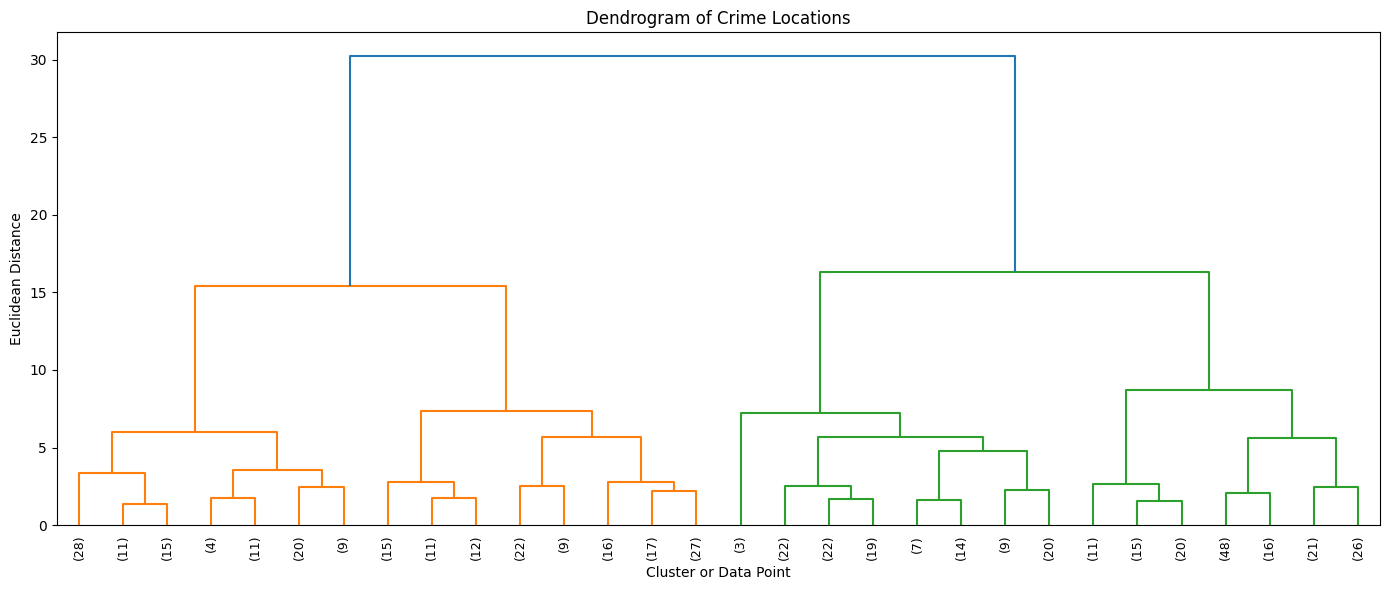

In [5]:
#Dendrogram for Agglomerative Clustering
dendrogram_size = min(500, len(X_scaled))

rng = np.random.default_rng(42)
dendrogram_indices = rng.choice(
    len(X_scaled),
    size=dendrogram_size,
    replace=False
)

X_dendrogram = X_scaled[dendrogram_indices]

Z = linkage(X_dendrogram, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=9
)
plt.title("Dendrogram of Crime Locations")
plt.xlabel("Cluster or Data Point")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

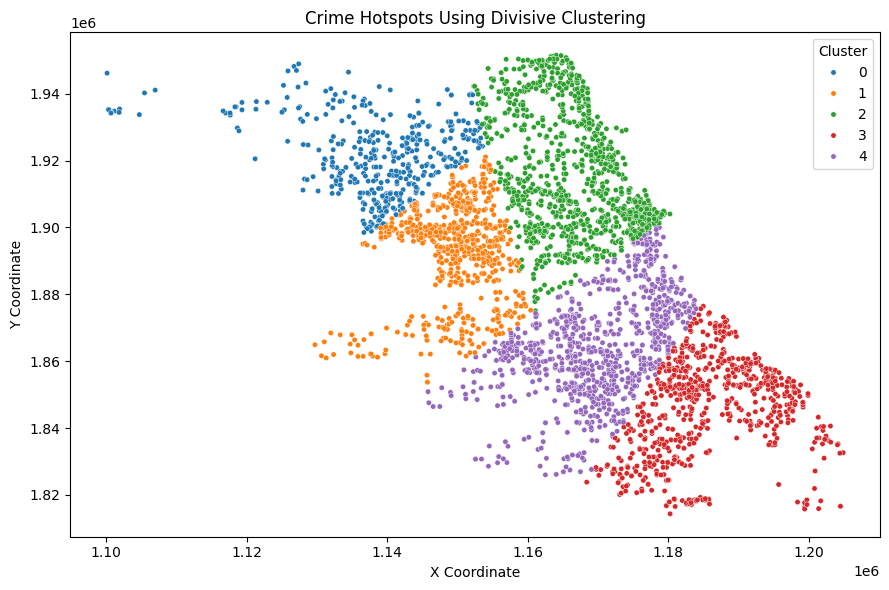

In [6]:
#Hierarchical clustering — Divisive approach
divisive = BisectingKMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

sample_df["Divisive_Cluster"] = (
    divisive.fit_predict(X_scaled)
)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=sample_df,
    x="X Coordinate",
    y="Y Coordinate",
    hue="Divisive_Cluster",
    palette="tab10",
    s=15
)
plt.title("Crime Hotspots Using Divisive Clustering")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

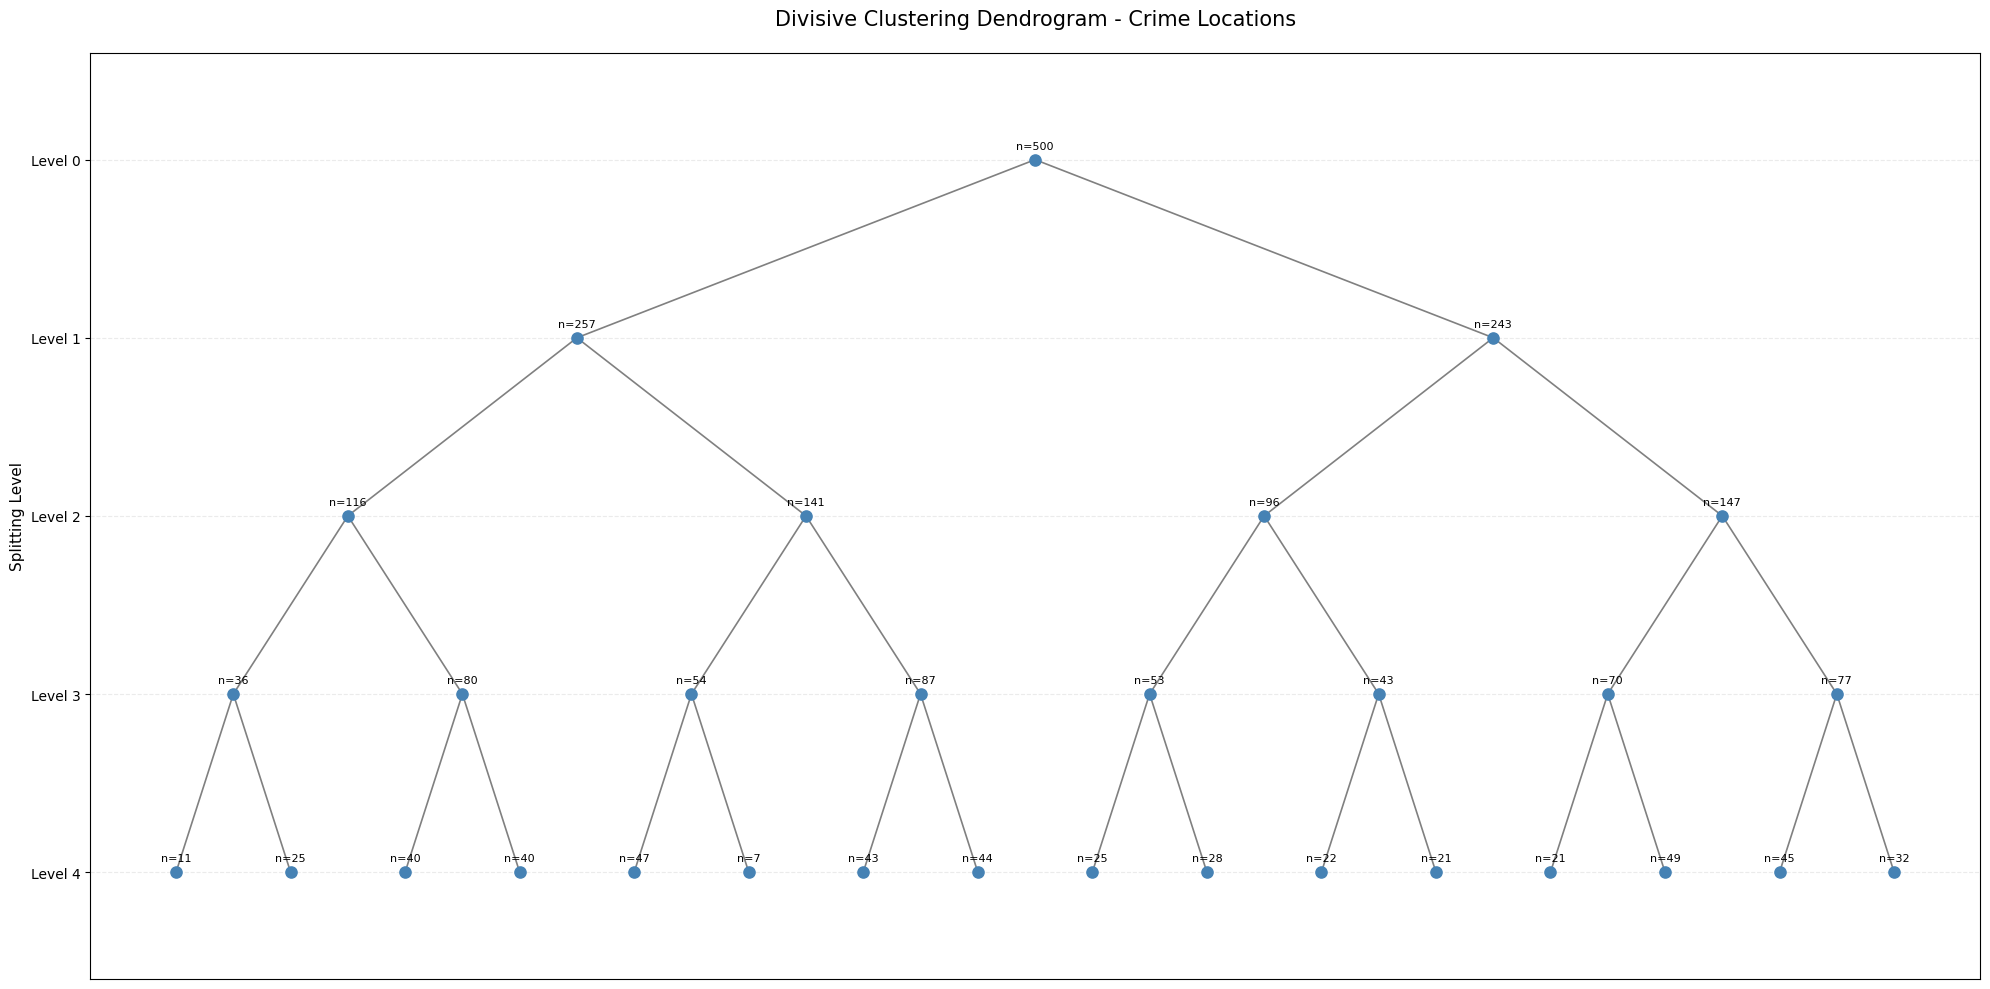

In [13]:
#Dendogram for divisive approach
from sklearn.cluster import BisectingKMeans
import numpy as np
import matplotlib.pyplot as plt

X_div = X_scaled[:500]

tree = {}
next_id = 0

def build_tree(indices, depth=0, max_depth=4):
    global next_id

    node = next_id
    next_id += 1

    tree[node] = {
        "size": len(indices),
        "depth": depth,
        "left": None,
        "right": None
    }

    if depth == max_depth or len(indices) < 2:
        return node

    model = BisectingKMeans(
        n_clusters=2,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_div[indices])

    left_indices = indices[labels == 0]
    right_indices = indices[labels == 1]

    if len(left_indices) == 0 or len(right_indices) == 0:
        return node

    tree[node]["left"] = build_tree(left_indices, depth + 1, max_depth)
    tree[node]["right"] = build_tree(right_indices, depth + 1, max_depth)

    return node


root = build_tree(np.arange(len(X_div)))

positions = {}
edges = []
leaf_position = [0]

def set_positions(node):
    left = tree[node]["left"]
    right = tree[node]["right"]

    if left is None and right is None:
        x = leaf_position[0]
        leaf_position[0] += 1
    else:
        set_positions(left)
        set_positions(right)
        x = (positions[left][0] + positions[right][0]) / 2

    y = -tree[node]["depth"]
    positions[node] = (x, y)

    if left is not None:
        edges.append((node, left))

    if right is not None:
        edges.append((node, right))


set_positions(root)

fig, ax = plt.subplots(figsize=(20, 10))

for parent, child in edges:
    x1, y1 = positions[parent]
    x2, y2 = positions[child]

    ax.plot(
        [x1, x2], [y1, y2],
        color="gray",
        linewidth=1.2
    )

for node, (x, y) in positions.items():
    ax.scatter(x, y, s=65, color="steelblue", zorder=3)

    ax.annotate(
        f"n={tree[node]['size']}",
        (x, y),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

ax.set_title(
    "Divisive Clustering Dendrogram - Crime Locations",
    fontsize=15,
    pad=20
)

ax.set_ylabel("Splitting Level", fontsize=11)
ax.set_yticks([0, -1, -2, -3, -4])
ax.set_yticklabels(
    ["Level 0", "Level 1", "Level 2", "Level 3", "Level 4"]
)

ax.set_xticks([])
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_ylim(-4.6, 0.6)

plt.tight_layout()
plt.show()

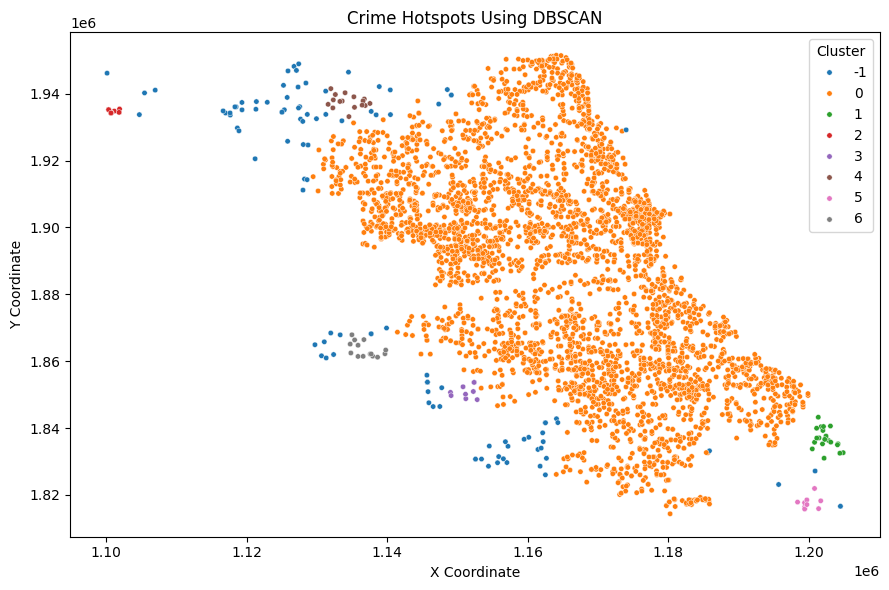

DBSCAN cluster labels:
DBSCAN_Cluster
-1     105
 0    3805
 1      21
 2      20
 3       9
 4      16
 5      10
 6      14
Name: count, dtype: int64


In [9]:
#Density-based clustering — DBSCAN
dbscan = DBSCAN(
    eps=0.15,
    min_samples=10
)

sample_df["DBSCAN_Cluster"] = (
    dbscan.fit_predict(X_scaled)
)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=sample_df,
    x="X Coordinate",
    y="Y Coordinate",
    hue="DBSCAN_Cluster",
    palette="tab10",
    s=15
)
plt.title("Crime Hotspots Using DBSCAN")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print("DBSCAN cluster labels:")
print(sample_df["DBSCAN_Cluster"].value_counts().sort_index())

In [10]:
#Evaluate clustering quality
def evaluate_clustering(X, labels, ignore_noise=False):
    labels = np.asarray(labels)

    valid = labels != -1 if ignore_noise else np.ones(len(labels), dtype=bool)

    X_valid = X[valid]
    labels_valid = labels[valid]

    unique_labels = np.unique(labels_valid)

    if len(unique_labels) < 2 or len(unique_labels) >= len(labels_valid):
        return np.nan, np.nan

    silhouette = silhouette_score(
        X_valid,
        labels_valid,
        sample_size=min(1000, len(X_valid)),
        random_state=42
    )

    db_index = davies_bouldin_score(
        X_valid,
        labels_valid
    )

    return silhouette, db_index


algorithms = {
    "K-Means": ("KMeans_Cluster", False),
    "Agglomerative": ("Agglomerative_Cluster", False),
    "Divisive": ("Divisive_Cluster", False),
    "DBSCAN": ("DBSCAN_Cluster", True)
}

results = []

for name, (column, ignore_noise) in algorithms.items():
    silhouette, db_index = evaluate_clustering(
        X_scaled,
        sample_df[column].to_numpy(),
        ignore_noise=ignore_noise
    )

    results.append({
        "Algorithm": name,
        "Number of Clusters": (
            sample_df[column].nunique()
            - (1 if ignore_noise and -1 in sample_df[column].values else 0)
        ),
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": db_index
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

    Algorithm  Number of Clusters  Silhouette Score  Davies-Bouldin Index
      K-Means                   5            0.4041                0.8258
Agglomerative                   5            0.3663                0.8904
     Divisive                   5            0.3271                0.9718
       DBSCAN                   7           -0.1520                0.5993


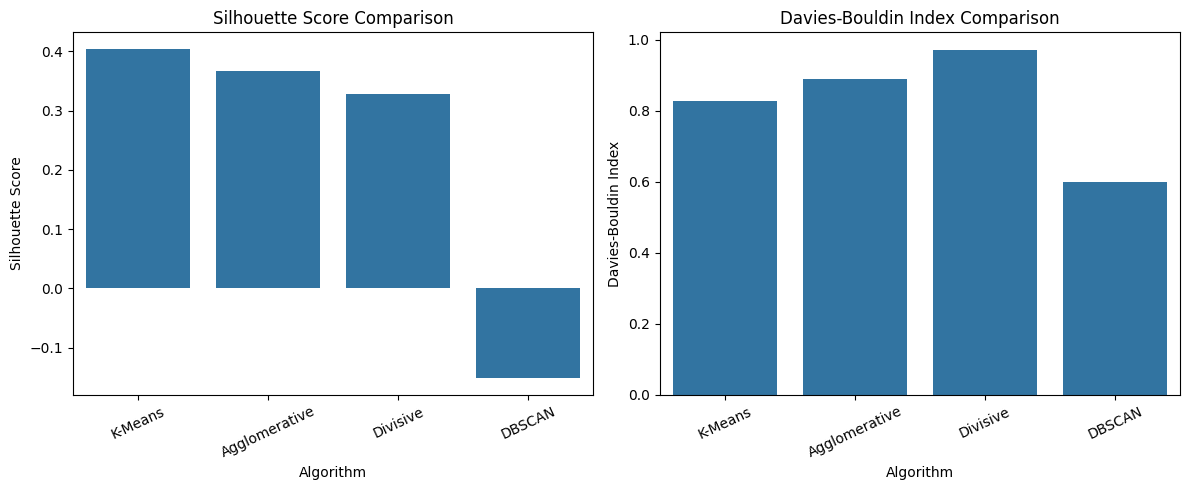

In [11]:
#Compare the algorithms visually
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=results_df,
    x="Algorithm",
    y="Silhouette Score",
    ax=axes[0]
)
axes[0].set_title("Silhouette Score Comparison")
axes[0].tick_params(axis="x", rotation=25)

sns.barplot(
    data=results_df,
    x="Algorithm",
    y="Davies-Bouldin Index",
    ax=axes[1]
)
axes[1].set_title("Davies-Bouldin Index Comparison")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

In [12]:
#Analyze the crime types within each K-Means cluster
cluster_summary = (
    sample_df[sample_df["KMeans_Cluster"] != -1]
    .groupby("KMeans_Cluster")
    .agg(
        Total_Incidents=("ID", "count"),
        Avg_X=("X Coordinate", "mean"),
        Avg_Y=("Y Coordinate", "mean")
    )
)

print("Geographic Cluster Summary:")
print(cluster_summary.round(2))

print("\nMost Common Crime Types in Each Cluster:")

for cluster in sorted(sample_df["KMeans_Cluster"].unique()):
    crimes = sample_df[
        sample_df["KMeans_Cluster"] == cluster
    ]["Primary Type"].value_counts().head(3)

    print(f"\nCluster {cluster}:")
    print(crimes.to_string())

Geographic Cluster Summary:
                Total_Incidents       Avg_X       Avg_Y
KMeans_Cluster                                         
0                           995  1184191.60  1850601.33
1                           912  1143461.12  1907257.92
2                           589  1162886.26  1929558.42
3                           688  1162804.13  1860059.77
4                           816  1172436.10  1897667.89

Most Common Crime Types in Each Cluster:

Cluster 0:
Primary Type
BATTERY            215
THEFT              139
CRIMINAL DAMAGE    139

Cluster 1:
Primary Type
BATTERY            203
THEFT              144
CRIMINAL DAMAGE    109

Cluster 2:
Primary Type
THEFT              211
BATTERY             80
CRIMINAL DAMAGE     61

Cluster 3:
Primary Type
BATTERY    147
THEFT      135
ASSAULT     81

Cluster 4:
Primary Type
THEFT              274
BATTERY            111
CRIMINAL DAMAGE     78


Crime Hotspot Ranking
 KMeans_Cluster  Total_Crimes        Avg_X        Avg_Y  Rank
              0           995 1.184192e+06 1.850601e+06     1
              1           912 1.143461e+06 1.907258e+06     2
              4           816 1.172436e+06 1.897668e+06     3
              3           688 1.162804e+06 1.860060e+06     4
              2           589 1.162886e+06 1.929558e+06     5


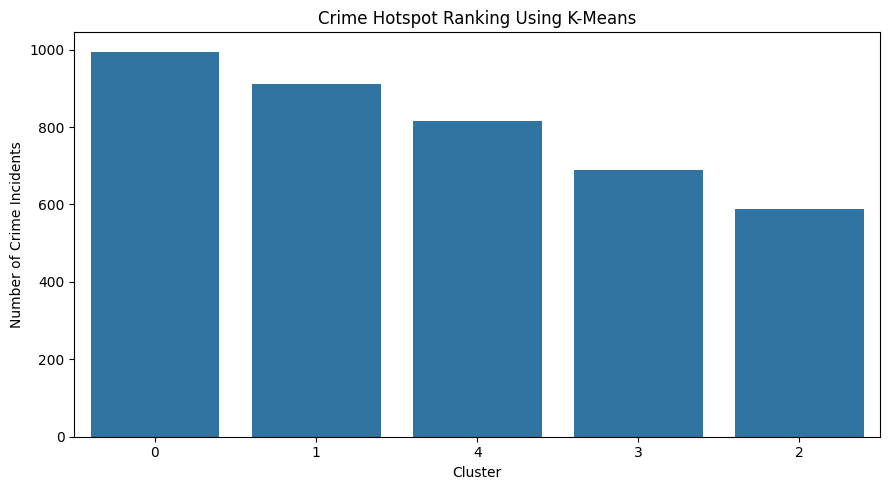

In [14]:
# Crime Hotspot Ranking
hotspot_summary = (
    sample_df.groupby("KMeans_Cluster")
    .agg(
        Total_Crimes=("ID", "count"),
        Avg_X=("X Coordinate", "mean"),
        Avg_Y=("Y Coordinate", "mean")
    )
    .sort_values("Total_Crimes", ascending=False)
    .reset_index()
)

hotspot_summary["Rank"] = (
    hotspot_summary["Total_Crimes"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

print("Crime Hotspot Ranking")
print(hotspot_summary.to_string(index=False))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=hotspot_summary,
    x="KMeans_Cluster",
    y="Total_Crimes",
    order=hotspot_summary.sort_values(
        "Total_Crimes", ascending=False
    )["KMeans_Cluster"]
)

plt.title("Crime Hotspot Ranking Using K-Means")
plt.xlabel("Cluster")
plt.ylabel("Number of Crime Incidents")
plt.tight_layout()
plt.show()